# THỐNG KÊ MÁY TÍNH VÀ ỨNG DỤNG (ĐTTX)

**Khoa Công nghệ Thông tin - ĐH Khoa học Tự nhiên TP. HCM ([fit@hcmus](https://www.fit.hcmus.edu.vn/))**

*Giảng viên: Vũ Quốc Hoàng (vqhoang@fit.hcmus.edu.vn)*

# BÀI 5 - TRỰC QUAN HÓA DỮ LIỆU (Phần 2)

**Nội dung**

* [Giới thiệu seaborn](#gioi_thieu)
* [Dữ liệu dạng dài và dạng rộng](#dang_dai_rong)
* [Phân bố của một biến](#phan_bo)
  * [Histogram và biểu đồ mật độ](#histogram)
  * [Boxplot và violin plot](#boxplot)
* [So sánh các nhóm](#so_sanh)
* [Quan hệ giữa các biến](#quan_he)
  * [Biểu đồ phân tán và đường hồi quy](#phan_tan)
  * [Heatmap](#heatmap)
  * [Pair plot](#pair_plot)
* [Chia nhỏ theo nhóm](#chia_nho)
* [Góc AI](#goc_ai)

**Tài liệu tham khảo**

* Chương 36 [Python Data Science Handbook (Jake VanderPlas)](https://www.amazon.com/Python-Data-Science-Handbook-Essential-dp-1098121228/dp/1098121228/)
* [seaborn: User guide and tutorial](https://seaborn.pydata.org/tutorial.html)
* [Fundamentals of Data Visualization (Claus O. Wilke)](https://clauswilke.com/dataviz/) (sách đọc trực tuyến miễn phí)

## <a name="gioi_thieu"/>Giới thiệu seaborn

[**seaborn**](https://seaborn.pydata.org/) là thư viện vẽ **biểu đồ thống kê** xây dựng trên Matplotlib. So với Matplotlib, seaborn:

* làm việc trực tiếp với `DataFrame`: chỉ cần chỉ ra **tên cột** cho trục hoành (`x`), trục tung (`y`), màu (`hue`), ...;
* tự tách nhóm, tự tính các thống kê (đếm, trung bình, khoảng tin cậy, mật độ) và tự vẽ chú thích;
* trả về đối tượng Matplotlib nên vẫn chỉnh tiếp được bằng các phương thức đã học ở Phần 1.

seaborn có hai loại hàm:

* **Mức biểu đồ** (axes-level): vẽ lên một biểu đồ `ax` (nhận tham số `ax=`), ví dụ `histplot`, `boxplot`, `scatterplot`.
* **Mức hình** (figure-level): tự tạo cả hình và có thể **chia nhỏ theo nhóm** bằng `col`, `row`, ví dụ `displot`, `catplot`, `relplot`.

| Câu hỏi | Hàm mức biểu đồ | Hàm mức hình |
|---|---|---|
| Phân bố | `histplot`, `kdeplot`, `ecdfplot` | `displot` |
| So sánh nhóm | `boxplot`, `violinplot`, `stripplot`, `barplot`, `pointplot`, `countplot` | `catplot` |
| Quan hệ, xu hướng | `scatterplot`, `lineplot`, `regplot` | `relplot`, `lmplot` |
| Tổng quan nhiều biến | `heatmap` | `pairplot` |

Nạp các thư viện và đặt giao diện chung (`set_theme`) cho các biểu đồ.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
print("seaborn", sns.__version__)

seaborn 0.13.2


Nạp các bộ dữ liệu: điện năng Đông Nam Á và Gapminder (Phần 1), Iris, Titanic.

In [2]:
dien = pd.read_csv("DienNang_DongNamA.csv")
gap = pd.read_csv("gapminder.csv")
g2007 = gap[gap.nam == 2007]

iris_names = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
iris = pd.read_csv("iris.data", names=iris_names)

titanic = pd.read_csv("TitanicSurvival.csv", index_col=0)
titanic["ket_qua"] = titanic.survived.map({"yes": "Sống sót", "no": "Thiệt mạng"})
titanic["gioi_tinh"] = titanic.sex.map({"female": "Nữ", "male": "Nam"})
titanic.head()

,survived,sex,age,passengerClass,ket_qua,gioi_tinh
"Allen, Miss. Elisabeth Walton",yes,female,29.0000,1st,Sống sót,Nữ
"Allison, Master. Hudson Trevor",yes,male,0.9167,1st,Sống sót,Nam
"Allison, Miss. Helen Loraine",no,female,2.0000,1st,Thiệt mạng,Nữ
"Allison, Mr. Hudson Joshua Crei",no,male,30.0000,1st,Thiệt mạng,Nam
"Allison, Mrs. Hudson J C (Bessi",no,female,25.0000,1st,Thiệt mạng,Nữ


Dữ liệu `TitanicSurvival.csv`: 1309 hành khách trên tàu Titanic (1912) với các cột `survived` (sống sót: `yes`/`no`), `sex` (giới tính), `age` (tuổi) và `passengerClass` (hạng vé: `1st`, `2nd`, `3rd`). Thêm hai cột tiếng Việt `ket_qua`, `gioi_tinh` để nhãn trên biểu đồ là tiếng Việt.

In [3]:
NGUON = ["than", "khi", "dau", "thuy_dien", "mat_troi", "gio", "sinh_khoi", "khac"]
TEN_NGUON = {"than": "Than", "khi": "Khí", "dau": "Dầu", "thuy_dien": "Thủy điện",
             "mat_troi": "Mặt trời", "gio": "Gió", "sinh_khoi": "Sinh khối", "khac": "Khác"}
MAU_NGUON = {"than": "#5a5a5a", "khi": "#f28e2b", "dau": "#8c564b", "thuy_dien": "#1f77b4",
             "mat_troi": "#c99700", "gio": "#17becf", "sinh_khoi": "#2ca02c", "khac": "#a6a6a6"}

## <a name="dang_dai_rong"/>Dữ liệu dạng dài và dạng rộng

seaborn (và Plotly ở Phần 3) làm việc tốt nhất với dữ liệu **dạng dài** (long format, tidy data): mỗi dòng là một quan sát, mỗi cột là một biến. Bảng `dien` đang ở **dạng rộng** (wide format): mỗi nguồn điện là một cột. Chuyển sang dạng dài bằng phương thức `melt` của pandas: giữ nguyên các cột định danh (`id_vars`), các cột còn lại được "xếp chồng" thành hai cột: tên cột cũ (`var_name`) và giá trị (`value_name`).

In [4]:
vn_rong = dien[dien.quoc_gia == "Việt Nam"][["nam"] + NGUON]
vn_dai = vn_rong.melt(id_vars="nam", var_name="nguon", value_name="san_luong")
vn_dai["nguon"] = vn_dai["nguon"].map(TEN_NGUON)

print("Dạng rộng:", vn_rong.shape, " Dạng dài:", vn_dai.shape)
vn_dai.head()

Dạng rộng: (26, 9)  Dạng dài: (208, 3)


,nam,nguon,san_luong
0,2000,Than,3.13
1,2001,Than,3.22
2,2002,Than,4.88
3,2003,Than,7.24
4,2004,Than,7.17


Với dữ liệu dạng dài, chỉ cần một lệnh: seaborn tự tách các nhóm theo cột `nguon`, tô màu và vẽ chú thích (so sánh với vòng lặp ở Phần 1).

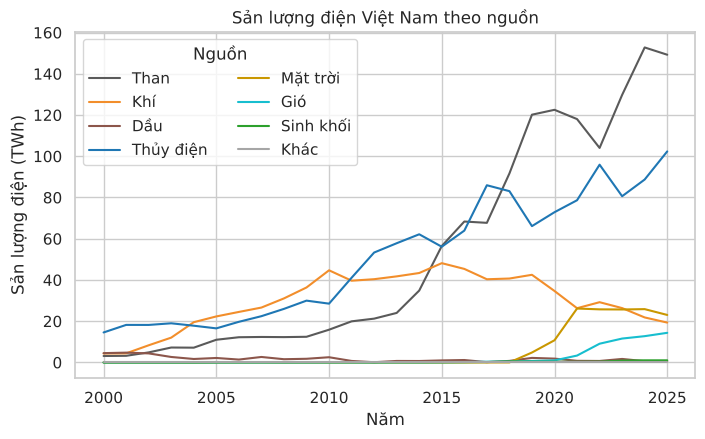

In [5]:
mau_theo_ten = {TEN_NGUON[k]: MAU_NGUON[k] for k in NGUON}

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.lineplot(data=vn_dai, x="nam", y="san_luong", hue="nguon",
             hue_order=[TEN_NGUON[k] for k in NGUON], palette=mau_theo_ten, ax=ax)
ax.set_title("Sản lượng điện Việt Nam theo nguồn")
ax.set_xlabel("Năm")
ax.set_ylabel("Sản lượng điện (TWh)")
ax.legend(title="Nguồn", ncol=2)
plt.show()

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Chuyển bảng `vn_dai` ngược lại về dạng rộng (gợi ý: `pivot`) và kiểm tra kết quả khớp với `vn_rong`.

In [6]:
# TODO:

## <a name="phan_bo"/>Phân bố của một biến

### <a name="histogram"/>Histogram và biểu đồ mật độ

Hàm [`histplot`](https://seaborn.pydata.org/generated/seaborn.histplot.html) vẽ histogram; `kde=True` vẽ thêm đường **mật độ** ước lượng (kernel density estimate).

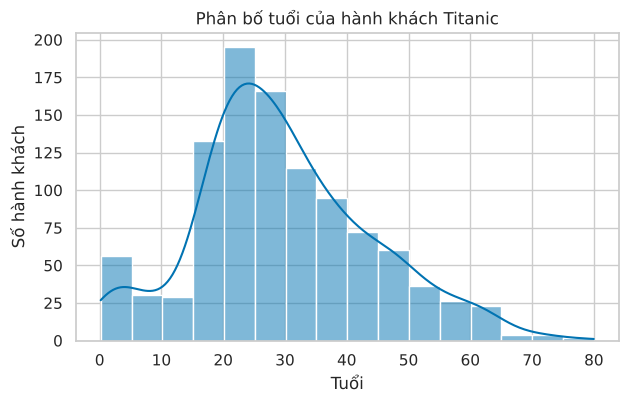

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=titanic, x="age", binwidth=5, kde=True, ax=ax)
ax.set_title("Phân bố tuổi của hành khách Titanic")
ax.set_xlabel("Tuổi")
ax.set_ylabel("Số hành khách")
plt.show()

Biểu đồ "đẹp" nhưng có bao nhiêu hành khách được vẽ? Cột `age` có giá trị thiếu và seaborn **lặng lẽ bỏ qua** chúng. Kiểm tra bằng cách cộng chiều cao các thanh:

In [8]:
tong_chieu_cao = sum(thanh.get_height() for thanh in ax.patches)
print("Tổng chiều cao các thanh:", int(tong_chieu_cao))
print("Số hành khách có tuổi:   ", titanic.age.notna().sum())
print("Số hành khách thiếu tuổi:", titanic.age.isna().sum(), "trên", len(titanic))

Tổng chiều cao các thanh: 1046
Số hành khách có tuổi:    1046
Số hành khách thiếu tuổi: 263 trên 1309


Biểu đồ chỉ thể hiện 1046 trên 1309 hành khách. Khi trình bày cần ghi rõ điều này (ví dụ trong tiêu đề hoặc chú thích).

So sánh phân bố của các nhóm bằng tham số `hue`. Với histogram, `multiple="stack"` xếp chồng các nhóm (thấy được tần số); với biểu đồ mật độ, `common_norm=False` chuẩn hóa riêng từng nhóm (so sánh **hình dạng** phân bố dù các nhóm có cỡ khác nhau).

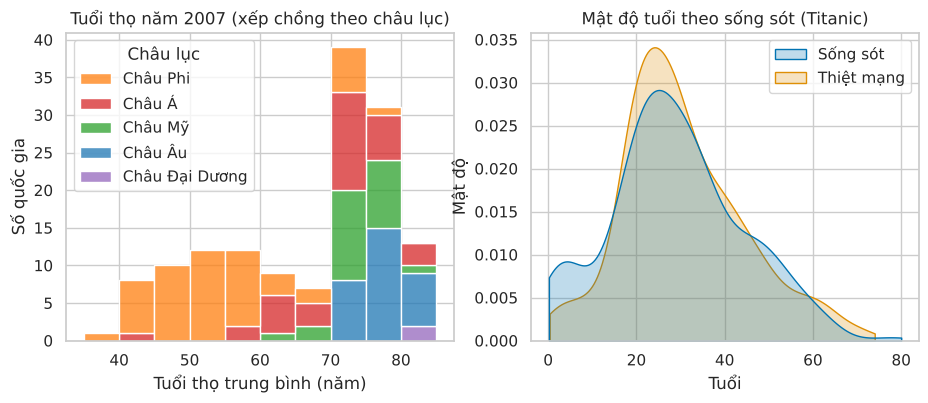

In [9]:
thu_tu = ["Châu Phi", "Châu Á", "Châu Mỹ", "Châu Âu", "Châu Đại Dương"]
MAU_CHAU = {"Châu Á": "#d62728", "Châu Âu": "#1f77b4", "Châu Phi": "#ff7f0e",
            "Châu Mỹ": "#2ca02c", "Châu Đại Dương": "#9467bd"}        # cùng màu với Phần 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=g2007, x="tuoi_tho", hue="chau_luc", hue_order=thu_tu, palette=MAU_CHAU,
             binwidth=5, binrange=(35, 85), multiple="stack", ax=ax1)
sns.move_legend(ax1, "upper left", title="Châu lục")
ax1.set_title("Tuổi thọ năm 2007 (xếp chồng theo châu lục)")
ax1.set_xlabel("Tuổi thọ trung bình (năm)")
ax1.set_ylabel("Số quốc gia")

sns.kdeplot(data=titanic, x="age", hue="ket_qua", common_norm=False, fill=True, cut=0, ax=ax2)
sns.move_legend(ax2, "upper right", title="")
ax2.set_title("Mật độ tuổi theo sống sót (Titanic)")
ax2.set_xlabel("Tuổi")
ax2.set_ylabel("Mật độ")
plt.show()

Biểu đồ bên trái giải thích nhóm tuổi thọ thấp ở Phần 1: hầu hết là các nước châu Phi. Bên phải: phân bố tuổi của hai nhóm khá giống nhau, riêng trẻ nhỏ có tỉ lệ sống sót cao hơn ("phụ nữ và trẻ em trước"). Tham số `cut=0` giữ đường mật độ trong phạm vi dữ liệu; nếu không, đường mật độ ước lượng có thể "tràn" sang cả tuổi âm.

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Vẽ histogram tuổi thọ của các nước năm 1952 và năm 2007 trên cùng một biểu đồ (gợi ý: lọc 2 năm rồi dùng `hue="nam"`). Nhận xét sự thay đổi sau 55 năm.

In [10]:
# TODO:

### <a name="boxplot"/>Boxplot và violin plot

**Boxplot** (biểu đồ hộp) tóm tắt phân bố bằng 5 con số:

* hộp kéo dài từ **tứ phân vị thứ nhất** $Q_1$ đến **tứ phân vị thứ ba** $Q_3$ (chứa 50% dữ liệu ở giữa); vạch trong hộp là **trung vị**;
* hai "râu" kéo tới điểm dữ liệu xa nhất nằm trong khoảng $1.5 \times IQR$ tính từ hộp, với $IQR = Q_3 - Q_1$;
* các điểm nằm ngoài râu được vẽ riêng: đó là các **ngoại lai tiềm năng** cần xem xét.

Boxplot rất tiện để **so sánh phân bố giữa các nhóm**.

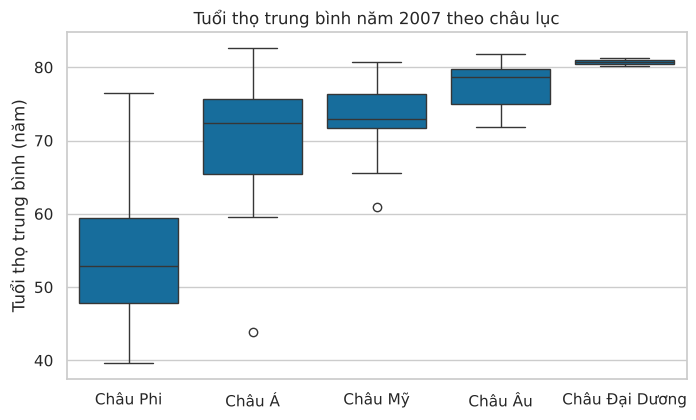

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=g2007, x="chau_luc", y="tuoi_tho", order=thu_tu, ax=ax)
ax.set_title("Tuổi thọ trung bình năm 2007 theo châu lục")
ax.set_xlabel("")
ax.set_ylabel("Tuổi thọ trung bình (năm)")
plt.show()

Kiểm chứng các con số mà hộp thể hiện bằng pandas:

In [12]:
g2007.groupby("chau_luc").tuoi_tho.describe().loc[thu_tu, ["count", "25%", "50%", "75%"]].round(1)

,count,25%,50%,75%
chau_luc,,,,
Châu Phi,52.0,47.8,52.9,59.4
Châu Á,33.0,65.5,72.4,75.6
Châu Mỹ,25.0,71.8,72.9,76.4
Châu Âu,30.0,75.0,78.6,79.8
Châu Đại Dương,2.0,80.5,80.7,81.0


Châu Đại Dương chỉ có **2 quốc gia** (Úc và New Zealand) nhưng vẫn được vẽ thành một "hộp" trông như các nhóm khác. Boxplot che mất cỡ mẫu; vẽ thêm từng điểm (`stripplot`) giúp thấy rõ điều này.

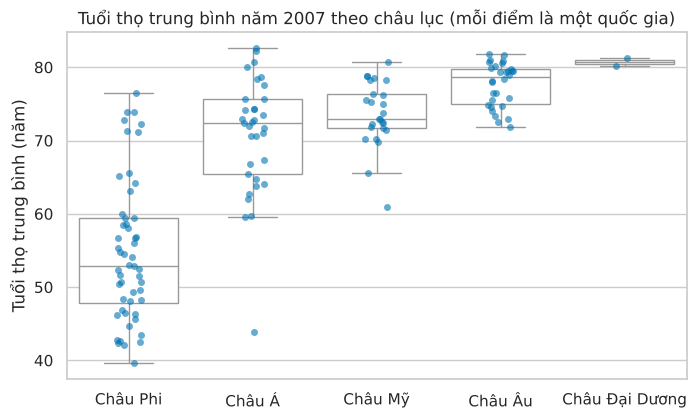

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=g2007, x="chau_luc", y="tuoi_tho", order=thu_tu, color="white", fliersize=0, ax=ax)
sns.stripplot(data=g2007, x="chau_luc", y="tuoi_tho", order=thu_tu, alpha=0.6, ax=ax)
ax.set_title("Tuổi thọ trung bình năm 2007 theo châu lục (mỗi điểm là một quốc gia)")
ax.set_xlabel("")
ax.set_ylabel("Tuổi thọ trung bình (năm)")
plt.show()

**Violin plot** kết hợp boxplot với biểu đồ mật độ, cho thấy cả hình dạng phân bố. Với `split=True`, mỗi "cây đàn" chia đôi cho hai nhóm của `hue`.

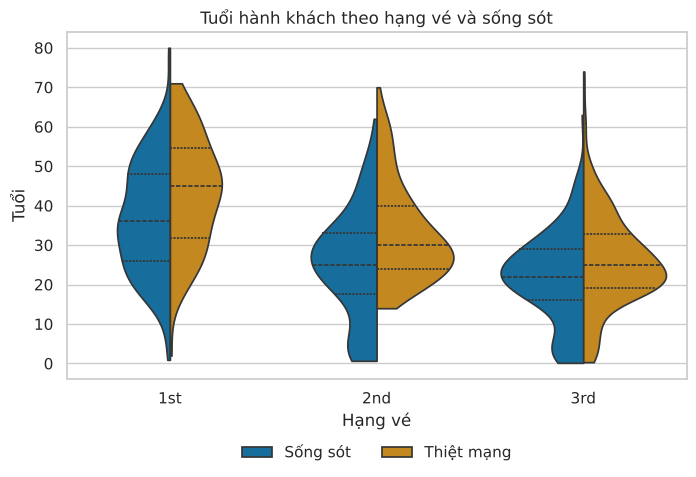

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=titanic, x="passengerClass", y="age", hue="ket_qua", split=True,
               order=["1st", "2nd", "3rd"], inner="quart", cut=0, ax=ax)
sns.move_legend(ax, "upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, title="", frameon=False)
ax.set_title("Tuổi hành khách theo hạng vé và sống sót")
ax.set_xlabel("Hạng vé")
ax.set_ylabel("Tuổi")
plt.show()

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Vẽ boxplot GDP bình quân năm 2007 theo châu lục (thử cả thang thường và thang log). Những nước nào là ngoại lai? (Gợi ý: tính $Q_1$, $Q_3$, $IQR$ bằng pandas để tìm.)

In [15]:
# TODO:

## <a name="so_sanh"/>So sánh các nhóm

[`countplot`](https://seaborn.pydata.org/generated/seaborn.countplot.html) đếm số quan sát của mỗi nhóm (biểu đồ thanh tần số).

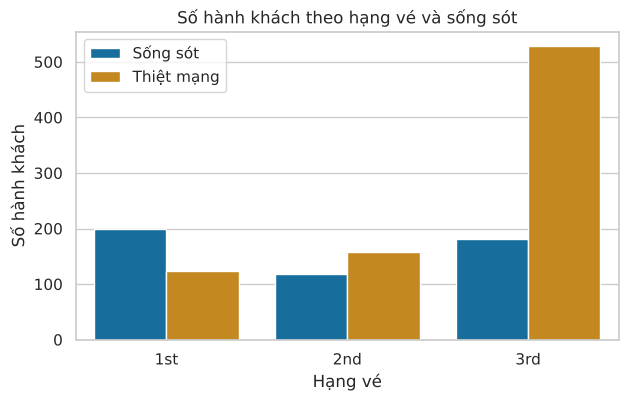

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=titanic, x="passengerClass", hue="ket_qua", order=["1st", "2nd", "3rd"], ax=ax)
sns.move_legend(ax, "upper left", title="")
ax.set_title("Số hành khách theo hạng vé và sống sót")
ax.set_xlabel("Hạng vé")
ax.set_ylabel("Số hành khách")
plt.show()

[`barplot`](https://seaborn.pydata.org/generated/seaborn.barplot.html) **không** đếm mà vẽ **trung bình** của biến `y` trong mỗi nhóm, kèm vạch **khoảng tin cậy 95%** (ước lượng bằng bootstrap). Nếu `y` là biến 0/1 thì trung bình chính là **tỉ lệ**.

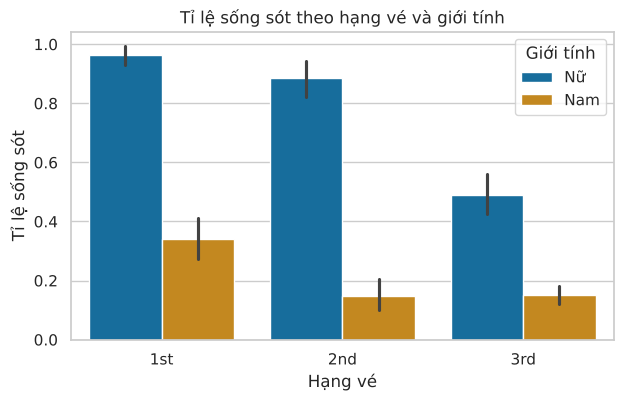

In [17]:
titanic["song_sot"] = (titanic.survived == "yes").astype(int)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=titanic, x="passengerClass", y="song_sot", hue="gioi_tinh",
            order=["1st", "2nd", "3rd"], ax=ax)
sns.move_legend(ax, "upper right", title="Giới tính")
ax.set_title("Tỉ lệ sống sót theo hạng vé và giới tính")
ax.set_xlabel("Hạng vé")
ax.set_ylabel("Tỉ lệ sống sót")
plt.show()

**Biết biểu đồ đang vẽ cái gì**: kiểm chứng chiều cao các thanh bằng pandas.

In [18]:
titanic.pivot_table(index="passengerClass", columns="gioi_tinh", values="song_sot", aggfunc="mean").round(3)

gioi_tinh,Nam,Nữ
passengerClass,,
1st,0.341,0.965
2nd,0.146,0.887
3rd,0.152,0.491


Phụ nữ có tỉ lệ sống sót cao hơn hẳn nam giới ở mọi hạng vé; nhìn chung hạng vé càng cao, tỉ lệ sống sót càng cao (riêng nam giới hạng 2 và hạng 3 gần như bằng nhau). Các vạch khoảng tin cậy khá ngắn so với chênh lệch giữa các nhóm, nên các chênh lệch này khó là ngẫu nhiên.

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Chia tuổi thành các nhóm (dưới 13, 13 - 17, 18 - 59, từ 60) bằng `pd.cut`, rồi vẽ tỉ lệ sống sót theo nhóm tuổi và giới tính. Kiểm chứng bằng `pivot_table`.

In [19]:
# TODO:

## <a name="quan_he"/>Quan hệ giữa các biến

### <a name="phan_tan"/>Biểu đồ phân tán và đường hồi quy

Biểu đồ phân tán với seaborn: màu (`hue`), kiểu điểm (`style`), kích thước (`size`) đều có thể gắn với một cột dữ liệu.

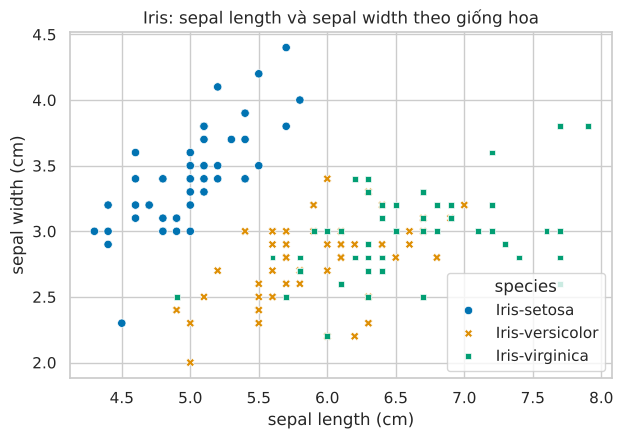

In [20]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=iris, x="sepal_length", y="sepal_width", hue="species", style="species", ax=ax)
ax.set_title("Iris: sepal length và sepal width theo giống hoa")
ax.set_xlabel("sepal length (cm)")
ax.set_ylabel("sepal width (cm)")
plt.show()

[`regplot`](https://seaborn.pydata.org/generated/seaborn.regplot.html) vẽ thêm **đường hồi quy** và dải tin cậy. Với `logx=True`, đường hồi quy có dạng $y = a + b \log x$, phù hợp với quan hệ giữa GDP và tuổi thọ ở Phần 1.

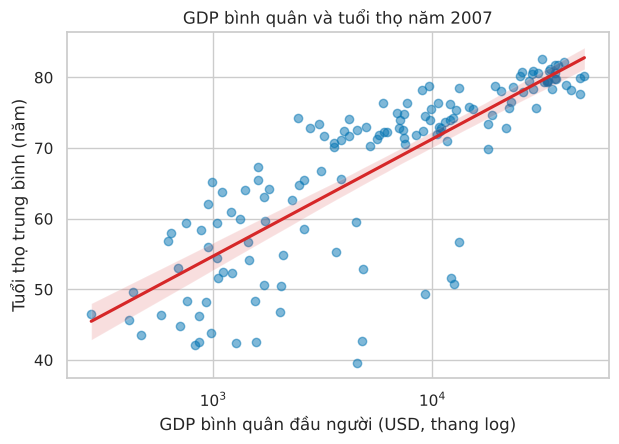

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.regplot(data=g2007, x="gdp_binh_quan", y="tuoi_tho", logx=True,
            scatter_kws=dict(alpha=0.5), line_kws=dict(color="tab:red"), ax=ax)
ax.set_xscale("log")
ax.set_title("GDP bình quân và tuổi thọ năm 2007")
ax.set_xlabel("GDP bình quân đầu người (USD, thang log)")
ax.set_ylabel("Tuổi thọ trung bình (năm)")
plt.show()

Nhớ bộ tứ Anscombe ở Phần 1: luôn nhìn các điểm dữ liệu, không chỉ nhìn đường hồi quy.

### <a name="heatmap"/>Heatmap

**Heatmap** tô màu các ô của một bảng số. Một ứng dụng phổ biến là **ma trận tương quan**: hệ số tương quan Pearson $r \in [-1, 1]$ đo mức độ quan hệ **tuyến tính** giữa từng cặp biến. Dùng thang màu **phân kỳ** (hai màu đối lập, ở giữa là màu trung tính ứng với $r = 0$).

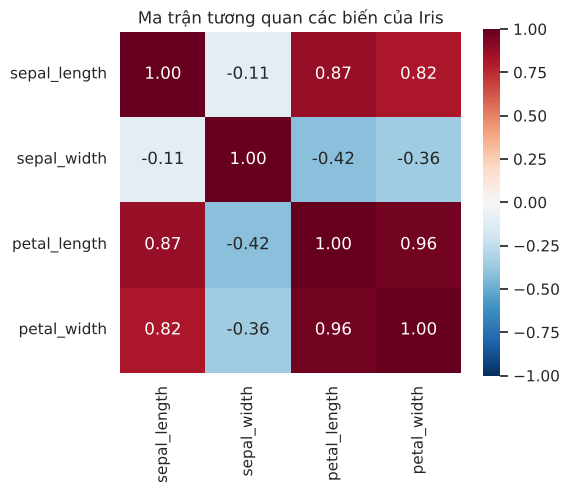

In [22]:
tuong_quan = iris.drop(columns="species").corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(tuong_quan, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r", square=True, ax=ax)
ax.set_title("Ma trận tương quan các biến của Iris")
plt.show()

Theo bảng trên, `sepal_length` và `sepal_width` gần như **không** tương quan ($r \approx -0.11$). Nhưng tính riêng trong từng giống hoa thì sao?

In [23]:
iris.groupby("species")[["sepal_length", "sepal_width"]].corr().round(2)

sepal_length  sepal_width
species                                                
Iris-setosa     sepal_length          1.00         0.75
                sepal_width           0.75         1.00
Iris-versicolor sepal_length          1.00         0.53
                sepal_width           0.53         1.00
Iris-virginica  sepal_length          1.00         0.46
                sepal_width           0.46         1.00

Trong **từng** giống hoa, hai biến tương quan **thuận** khá rõ ($r$ từ 0.46 đến 0.75, như có thể thấy ở biểu đồ phân tán phía trên), nhưng gộp chung lại thì tương quan gần bằng 0 vì các giống hoa nằm ở các vùng khác nhau. Một con số tóm tắt trên dữ liệu gộp có thể che giấu quan hệ trong từng nhóm, và tương quan không phải là quan hệ nhân quả.

Heatmap cũng dùng được cho bảng tổng hợp bất kỳ. Ví dụ: tỉ trọng điện than (%) theo quốc gia và năm (đến 2024 vì một số nước chưa có số liệu 2025), dùng thang màu **tuần tự** (một màu, từ nhạt đến đậm).

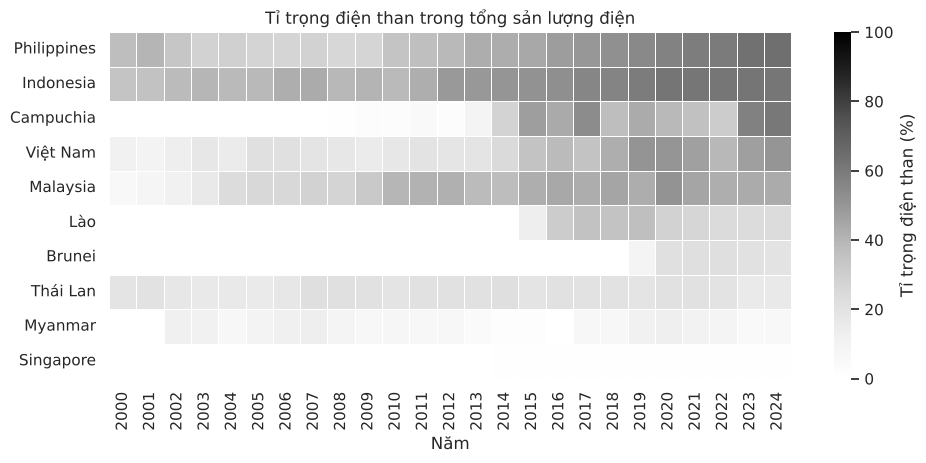

In [24]:
ti_trong_than = (dien[dien.nam <= 2024]
                 .assign(ti_trong=lambda d: 100 * d.than / d.san_luong)
                 .pivot(index="quoc_gia", columns="nam", values="ti_trong"))
ti_trong_than = ti_trong_than.loc[ti_trong_than[2024].sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(ti_trong_than, cmap="Greys", vmin=0, vmax=100, linewidths=0.5,
            cbar_kws=dict(label="Tỉ trọng điện than (%)"), ax=ax)
ax.set_title("Tỉ trọng điện than trong tổng sản lượng điện")
ax.set_xlabel("Năm")
ax.set_ylabel("")
plt.show()

### <a name="pair_plot"/>Pair plot

[`pairplot`](https://seaborn.pydata.org/generated/seaborn.pairplot.html) khảo sát "chung" các biến: biểu đồ phân tán cho từng cặp biến và phân bố của từng biến trên đường chéo.

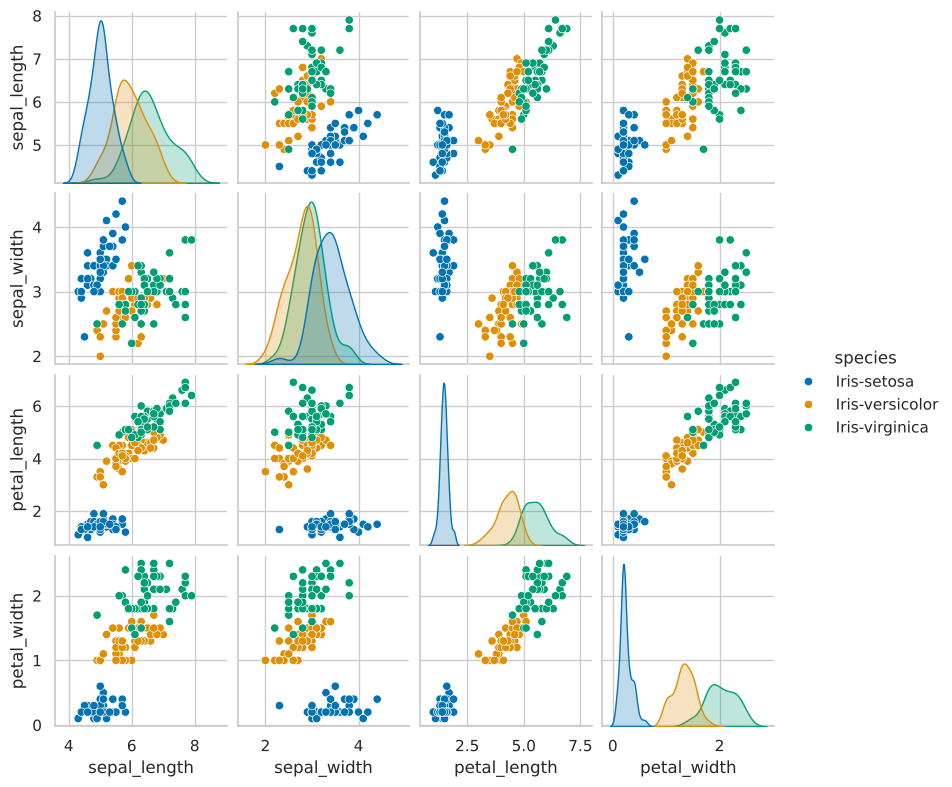

In [25]:
sns.pairplot(iris, hue="species", height=2)
plt.show()

Các giống hoa phân cách nhau khá tốt theo `petal_length` và `petal_width`: ta có thể dùng hai biến này để phân biệt 3 giống hoa Iris (Bài 7).

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Vẽ ma trận tương quan cho các biến `tuoi_tho`, `dan_so`, `gdp_binh_quan` của Gapminder năm 2007, rồi tính lại với $\log$ của `gdp_binh_quan` và $\log$ của `dan_so`. Vì sao hệ số tương quan thay đổi? (Gợi ý: xem lại biểu đồ phân tán ở Phần 1.)

In [26]:
# TODO:

## <a name="chia_nho"/>Chia nhỏ theo nhóm

Các hàm mức hình (`relplot`, `displot`, `catplot`) vẽ **nhiều biểu đồ nhỏ** (small multiples) chỉ bằng tham số `col`, `row` (`col_wrap` để xuống dòng). Ví dụ: sản lượng điện của 10 nước, mỗi nước một biểu đồ.

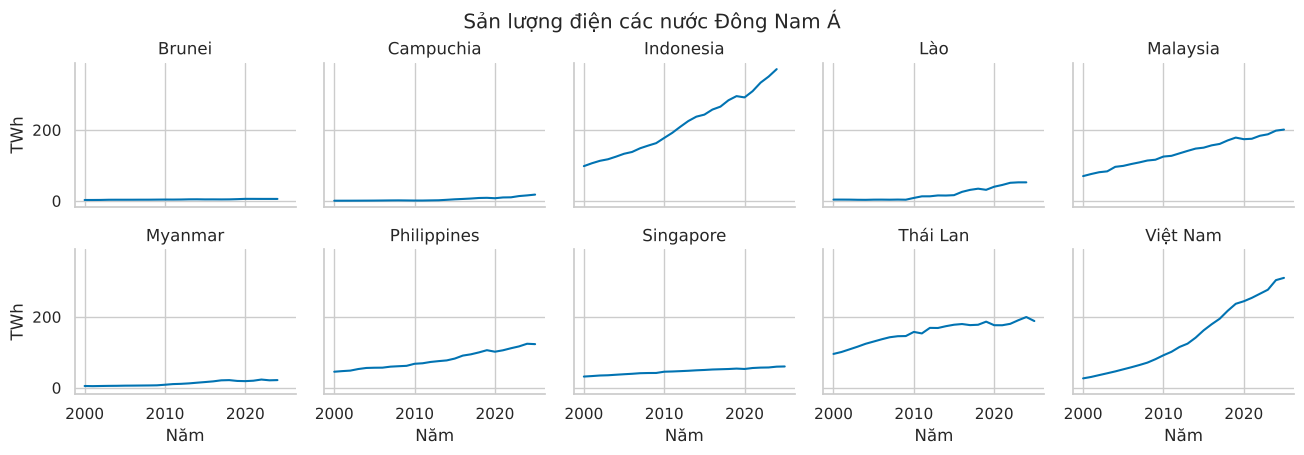

In [27]:
luoi = sns.relplot(data=dien, x="nam", y="san_luong", col="quoc_gia", col_wrap=5,
                   kind="line", height=2.2, aspect=1.2)
luoi.set_titles("{col_name}")
luoi.set_axis_labels("Năm", "TWh")
luoi.figure.suptitle("Sản lượng điện các nước Đông Nam Á", y=1.03)
plt.show()

Các biểu đồ nhỏ dùng chung thang trục nên so sánh được độ lớn. Muốn so sánh **tốc độ tăng** của các nước nhỏ thì có thể cho mỗi biểu đồ một thang riêng (`facet_kws=dict(sharey=False)`), nhưng khi đó phải ghi rõ để người đọc không so sánh độ cao giữa các biểu đồ.

Ví dụ khác: phân bố tuổi thọ của các nước qua các năm.

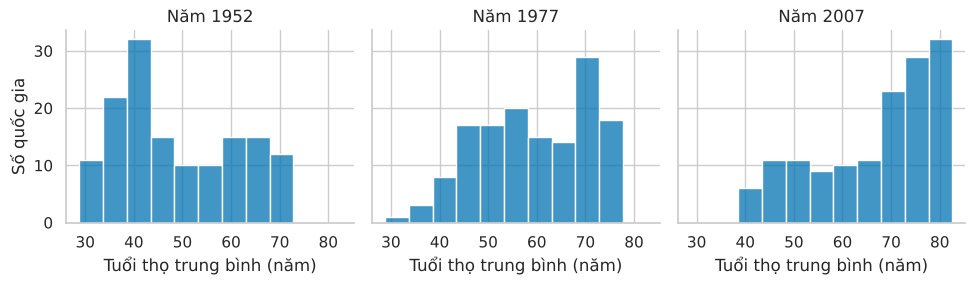

In [28]:
luoi = sns.displot(data=gap[gap.nam.isin([1952, 1977, 2007])], x="tuoi_tho", col="nam",
                   binwidth=5, height=3, aspect=1.1)
luoi.set_titles("Năm {col_name}")
luoi.set_axis_labels("Tuổi thọ trung bình (năm)", "Số quốc gia")
plt.show()

Phân bố dịch dần sang phải: sau 55 năm, phần lớn các nước đã có tuổi thọ trên 70.

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Dùng `catplot(kind="bar", ...)` vẽ tỉ lệ sống sót theo hạng vé, chia thành các biểu đồ nhỏ theo giới tính (`col="gioi_tinh"`).

In [29]:
# TODO:

## <a name="goc_ai"/>Góc AI

seaborn thay đổi khá nhiều qua các phiên bản, trong khi AI học từ rất nhiều code cũ. Hai lỗi hay gặp trong code seaborn do AI viết: dùng **hàm cũ** và dùng **tham số cũ**.

In [30]:
import warnings

with warnings.catch_warnings(record=True) as canh_bao:
    warnings.simplefilter("always")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
    sns.distplot(titanic.age.dropna(), ax=ax1)                                  # hàm cũ
    sns.barplot(data=titanic, x="passengerClass", y="song_sot", ci=95, ax=ax2)  # tham số cũ
    plt.close(fig)

for cb in canh_bao:
    print(cb.category.__name__, "-", str(cb.message).strip().splitlines()[0])

UserWarning - `distplot` is a deprecated function and will be removed in seaborn v0.14.0.
FutureWarning - The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.


`distplot` đã bị thay bằng `histplot`, `kdeplot`, `displot` và sẽ bị xóa; tham số `ci` đã được thay bằng `errorbar`. Code cũ hôm nay chỉ cảnh báo, nhưng ở phiên bản sau sẽ báo lỗi. Vì vậy, khi ra lệnh hãy **ghi rõ phiên bản** (in bằng `sns.__version__`) và đọc kỹ các cảnh báo.

Lỗi thứ hai khó thấy hơn: **không biết biểu đồ đang vẽ cái gì**. Ví dụ: AI dùng `barplot` để "so sánh số hành khách" (thực ra `barplot` vẽ trung bình), hay dùng `countplot` khi cần tỉ lệ. Hãy nhờ AI giải thích từng thành phần của biểu đồ (thanh là gì, vạch đen là gì, các giá trị thiếu được xử lý thế nào) rồi kiểm chứng bằng pandas như đã làm ở trên.

```text
Tôi dùng seaborn <phiên bản> với DataFrame `titanic` có các cột: <dán kết quả titanic.info()>.
Vẽ biểu đồ so sánh tỉ lệ sống sót theo hạng vé và giới tính.
Sau đó giải thích: chiều cao mỗi thanh và vạch đen trên thanh biểu diễn đại lượng gì,
được tính thế nào, giá trị thiếu được xử lý ra sao; và cho code pandas để kiểm chứng các con số.
```

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Dùng lệnh trên với một công cụ AI. Chạy code AI đưa ra, đối chiếu với kết quả `pivot_table` ở phần So sánh các nhóm. AI có dùng hàm, tham số cũ không? Giải thích của AI về vạch đen có đúng không?

In [31]:
# TODO: